In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

# reading data

In [3]:
data = pd.read_csv("application_data.csv")
data

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,456251,0,Cash loans,M,N,N,0,157500.0,254700.0,27558.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307507,456252,0,Cash loans,F,N,Y,0,72000.0,269550.0,12001.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
307508,456253,0,Cash loans,F,N,Y,0,153000.0,677664.0,29979.0,...,0,0,0,0,1.0,0.0,0.0,1.0,0.0,1.0
307509,456254,1,Cash loans,F,N,Y,0,171000.0,370107.0,20205.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
number_of_normal = (data.TARGET == 0).sum()
number_of_fraud = (data.TARGET == 1).sum()

print(f"Number of rows = {data.shape[0]}\nNumber of columns = {data.shape[1]}")
print(f"Number of normal = {number_of_normal}")
print(f"Number of fraud = {number_of_fraud}")
print(f"Percentage of fraud = {(number_of_fraud / data.shape[0]) * 100:.3f}")

Number of rows = 307511
Number of columns = 122
Number of normal = 282686
Number of fraud = 24825
Percentage of fraud = 8.073


# dropping id and columns with more than 40 percent null

In [5]:
data = data.drop("SK_ID_CURR", axis=1)

percentage_of_nulls = (data.isnull().sum() / data.shape[0]) * 100
columns_with_many_nulls = percentage_of_nulls[percentage_of_nulls > 40].index

data = data.drop(columns_with_many_nulls, axis=1)
print(f"Number of dropped columns = {len(columns_with_many_nulls)}\nNumber of remaining columns = {data.shape[1]}")

Number of dropped columns = 49
Number of remaining columns = 72


# 365243 in DAYS_EMPLOYED is not a real value

In [6]:
data["DAYS_EMPLOYED"] = data["DAYS_EMPLOYED"].replace(365243, np.nan)

# train, validation and test indices (70, 10, 20)

In [7]:
y = data.TARGET.to_numpy()
indices = np.arange(data.shape[0])

train_indices, test_indices = train_test_split(indices, test_size=0.2, stratify=y, random_state=42)
train_indices, val_indices = train_test_split(train_indices, test_size=0.125, stratify=y[train_indices], random_state=42)

print(f"Number of train = {len(train_indices)}\nNumber of val = {len(val_indices)}\nNumber of test = {len(test_indices)}")

Number of train = 215257
Number of val = 30751
Number of test = 61503


# filling nulls with median and mode of train

In [8]:
numerical_columns = data.select_dtypes(include="number").columns.drop("TARGET")
categorical_columns = data.select_dtypes(exclude="number").columns

print(f"Number of numerical columns = {len(numerical_columns)}\nNumber of categorical columns = {len(categorical_columns)}")

Number of numerical columns = 59
Number of categorical columns = 12


In [9]:
train_data = data.iloc[train_indices]

for column in numerical_columns:
    data[column] = data[column].fillna(train_data[column].median())

for column in categorical_columns:
    data[column] = data[column].fillna(train_data[column].mode()[0])

print(f"Number of nulls = {data.isnull().sum().sum()}")

Number of nulls = 0


# encoding categorical columns

In [10]:
data = pd.get_dummies(data, columns=list(categorical_columns))
print(f"Number of columns after encoding = {data.shape[1]}")

Number of columns after encoding = 184


# train, validation and test split

In [11]:
X = data.drop("TARGET", axis=1).to_numpy(dtype=np.float64)

X_train, y_train = X[train_indices], y[train_indices]
X_val, y_val = X[val_indices], y[val_indices]
X_test, y_test = X[test_indices], y[test_indices]

print(f"X_train shape is {X_train.shape}\nX_val shape is {X_val.shape}\nX_test shape is {X_test.shape}\n")
print(f"Number of fraud in train = {y_train.sum()}\nNumber of fraud in val = {y_val.sum()}\nNumber of fraud in test = {y_test.sum()}")

X_train shape is (215257, 183)
X_val shape is (30751, 183)
X_test shape is (61503, 183)

Number of fraud in train = 17378
Number of fraud in val = 2482
Number of fraud in test = 4965


# scaling with normal rows of train

In [12]:
scaler = StandardScaler()
scaler.fit(X_train[y_train == 0])

X_train = scaler.transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

# first models

In [13]:
def evaluate(y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    return accuracy, precision, recall, f1

In [14]:
logistic = LogisticRegression(max_iter=1000)
logistic.fit(X_train, y_train)
predicted_logistic = logistic.predict(X_test)

accuracy_logistic, precision_logistic, recall_logistic, f1_logistic = evaluate(y_test, predicted_logistic)

print(f"accuracy = {accuracy_logistic:.4f}\nprecision = {precision_logistic:.4f}\nrecall = {recall_logistic:.4f}\nf1 = {f1_logistic:.4f}")
confusion_matrix(y_test, predicted_logistic)

accuracy = 0.9195
precision = 0.5741
recall = 0.0125
f1 = 0.0244


array([[56492,    46],
       [ 4903,    62]])

In [15]:
forest = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
forest.fit(X_train, y_train)
predicted_forest = forest.predict(X_test)

accuracy_forest, precision_forest, recall_forest, f1_forest = evaluate(y_test, predicted_forest)

print(f"accuracy = {accuracy_forest:.4f}\nprecision = {precision_forest:.4f}\nrecall = {recall_forest:.4f}\nf1 = {f1_forest:.4f}")
confusion_matrix(y_test, predicted_forest)

accuracy = 0.9193
precision = 0.4000
recall = 0.0004
f1 = 0.0008


array([[56535,     3],
       [ 4963,     2]])

# a model that always says normal

In [16]:
always_normal = np.zeros(y_test.shape[0])
print(f"accuracy = {accuracy_score(y_test, always_normal):.4f}\nrecall = {recall_score(y_test, always_normal):.4f}")

accuracy = 0.9193
recall = 0.0000


# normal rows for training autoencoders

In [17]:
X_train_normal = X_train[y_train == 0]
X_val_normal = X_val[y_val == 0]

input_dim = X_train.shape[1]
coding_size = 8

print(f"X_train_normal shape is {X_train_normal.shape}\nX_val_normal shape is {X_val_normal.shape}")

X_train_normal shape is (197879, 183)
X_val_normal shape is (28269, 183)


# Variational Autoencoder and Autoencoder

In [18]:
class Encoder(tf.keras.Model):
    def __init__(self, coding_size):
        super().__init__()
        self.fc1 = tf.keras.layers.Dense(256, activation="relu")
        self.fc2 = tf.keras.layers.Dense(128, activation="relu")
        self.fc3 = tf.keras.layers.Dense(64,  activation="relu")
        self.fc4 = tf.keras.layers.Dense(32,  activation="relu")
        self.fc5 = tf.keras.layers.Dense(16,  activation="relu")
        self.mu_layer      = tf.keras.layers.Dense(coding_size)
        self.log_var_layer = tf.keras.layers.Dense(coding_size)

    def call(self, inputs):
        x = self.fc5(self.fc4(self.fc3(self.fc2(self.fc1(inputs)))))
        return self.mu_layer(x), self.log_var_layer(x)


class Sample(tf.keras.layers.Layer):
    def call(self, inputs):
        mu, log_var = inputs
        eps = tf.random.normal(shape=tf.shape(mu))
        return mu + tf.exp(0.5 * log_var) * eps          # reparameterisation trick


class Decoder(tf.keras.Model):
    def __init__(self, output_dim):
        super().__init__()
        self.fc1 = tf.keras.layers.Dense(16,  activation="relu")
        self.fc2 = tf.keras.layers.Dense(32,  activation="relu")
        self.fc3 = tf.keras.layers.Dense(64,  activation="relu")
        self.fc4 = tf.keras.layers.Dense(128, activation="relu")
        self.fc5 = tf.keras.layers.Dense(256, activation="relu")
        self.output_layer = tf.keras.layers.Dense(output_dim)   # linear output

    def call(self, inputs):
        x = self.fc5(self.fc4(self.fc3(self.fc2(self.fc1(inputs)))))
        return self.output_layer(x)


class VariationalAutoEncoder(tf.keras.Model):
    def __init__(self, input_dim, coding_size, kl_weight=1.0):
        super().__init__()
        self.encoder, self.sample, self.decoder = Encoder(coding_size), Sample(), Decoder(input_dim)
        self.kl_weight = kl_weight

    def call(self, inputs):
        mu, log_var = self.encoder(inputs)
        decoded = self.decoder(self.sample([mu, log_var]))
        kl = -0.5 * tf.reduce_mean(1 + log_var - tf.square(mu) - tf.exp(log_var))
        self.add_loss(self.kl_weight * kl)
        return decoded

    def reconstruct(self, x):
        mu, _ = self.encoder(x)          # deterministic: decode the mean, no sampling noise
        return self.decoder(mu)


class AutoEncoder(tf.keras.Model):
    def __init__(self, input_dim, coding_size):
        super().__init__()
        enc = [tf.keras.layers.Dense(u, activation="relu") for u in (256, 128, 64, 32, 16)]
        dec = [tf.keras.layers.Dense(u, activation="relu") for u in (16, 32, 64, 128, 256)]
        self.encoder = tf.keras.Sequential(enc + [tf.keras.layers.Dense(coding_size)])
        self.decoder = tf.keras.Sequential(dec + [tf.keras.layers.Dense(input_dim)])

    def call(self, inputs):
        return self.decoder(self.encoder(inputs))

    def reconstruct(self, x):
        return self(x)

# training

In [19]:
def train(model, seed, max_iter=30, batch_size=256):

    tf.keras.utils.set_random_seed(seed)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="mse")
    early_stopping = tf.keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)

    history = model.fit(X_train_normal, X_train_normal, validation_data=(X_val_normal, X_val_normal),
                        epochs=max_iter, batch_size=batch_size, callbacks=[early_stopping], verbose=0)

    return history

# reconstruction error

In [20]:
def reconstruction_error(model, X, batch_size=8192):

    reconstructed = np.empty(X.shape, dtype=np.float32)

    for start in range(0, X.shape[0], batch_size):
        end = min(start + batch_size, X.shape[0])
        reconstructed[start : end] = model.reconstruct(X[start : end]).numpy()

    return np.mean((X - reconstructed) ** 2, axis=1)

# threshold is 99th percentile of error of normal validation rows

In [21]:
def scores_of_model(error_val, error_test):

    threshold = np.percentile(error_val[y_val == 0], 99)
    predicted = np.where(error_test > threshold, 1, 0)

    pr_auc = average_precision_score(y_test, error_test)
    roc_auc = roc_auc_score(y_test, error_test)
    recall = recall_score(y_test, predicted)
    precision = precision_score(y_test, predicted, zero_division=0)

    return pr_auc, roc_auc, recall, precision

# PCA

In [22]:
pca = PCA(n_components=coding_size)
pca.fit(X_train_normal)

error_pca_val = np.mean((X_val - pca.inverse_transform(pca.transform(X_val))) ** 2, axis=1)
error_pca_test = np.mean((X_test - pca.inverse_transform(pca.transform(X_test))) ** 2, axis=1)

pr_auc_pca, roc_auc_pca, recall_pca, precision_pca = scores_of_model(error_pca_val, error_pca_test)
print(f"PR AUC = {pr_auc_pca:.4f}\nROC AUC = {roc_auc_pca:.4f}\nrecall = {recall_pca:.4f}\nprecision = {precision_pca:.4f}")

PR AUC = 0.0802
ROC AUC = 0.5085
recall = 0.0093
precision = 0.0707


# Autoencoder and Variational Autoencoder with 6 seeds

In [23]:
seeds = [0, 1, 2, 3, 4, 5]
results = [["PCA", 0, pr_auc_pca, roc_auc_pca, recall_pca, precision_pca]]

for seed in seeds:

    tf.keras.utils.set_random_seed(seed)
    autoencoder = AutoEncoder(input_dim, coding_size)
    history_ae = train(autoencoder, seed)

    error_ae_val = reconstruction_error(autoencoder, X_val)
    error_ae_test = reconstruction_error(autoencoder, X_test)
    pr_auc, roc_auc, recall, precision = scores_of_model(error_ae_val, error_ae_test)
    results.append(["AE", seed, pr_auc, roc_auc, recall, precision])
    print(f"AE  seed {seed} -- PR AUC {pr_auc:.4f} -- recall {recall:.4f}")

    tf.keras.utils.set_random_seed(seed)
    vae = VariationalAutoEncoder(input_dim, coding_size, kl_weight=0.001)
    history_vae = train(vae, seed)

    error_vae_val = reconstruction_error(vae, X_val)
    error_vae_test = reconstruction_error(vae, X_test)
    pr_auc, roc_auc, recall, precision = scores_of_model(error_vae_val, error_vae_test)
    results.append(["VAE", seed, pr_auc, roc_auc, recall, precision])
    print(f"VAE seed {seed} -- PR AUC {pr_auc:.4f} -- recall {recall:.4f}")

AE  seed 0 -- PR AUC 0.0814 -- recall 0.0083
VAE seed 0 -- PR AUC 0.0821 -- recall 0.0097
AE  seed 1 -- PR AUC 0.0817 -- recall 0.0093
VAE seed 1 -- PR AUC 0.0819 -- recall 0.0091
AE  seed 2 -- PR AUC 0.0817 -- recall 0.0091
VAE seed 2 -- PR AUC 0.0811 -- recall 0.0077
AE  seed 3 -- PR AUC 0.0815 -- recall 0.0073
VAE seed 3 -- PR AUC 0.0824 -- recall 0.0117
AE  seed 4 -- PR AUC 0.0817 -- recall 0.0089
VAE seed 4 -- PR AUC 0.0816 -- recall 0.0081
AE  seed 5 -- PR AUC 0.0818 -- recall 0.0083
VAE seed 5 -- PR AUC 0.0820 -- recall 0.0085


# Results aggregated

In [24]:
dataFrame_of_results = pd.DataFrame(results, columns=["Model", "Seed", "PR_AUC", "ROC_AUC", "Recall", "Precision"])
dataFrame_of_results

,Model,Seed,PR_AUC,ROC_AUC,Recall,Precision
0,PCA,0,0.080196,0.508477,0.009265,0.070661
1,AE,0,0.081436,0.515207,0.008258,0.062691
2,VAE,0,0.082121,0.516806,0.009668,0.078431
3,AE,1,0.081738,0.516327,0.009265,0.067847
4,VAE,1,0.081853,0.516167,0.009063,0.065598
5,AE,2,0.081735,0.514343,0.009063,0.066176
6,VAE,2,0.081149,0.512639,0.007654,0.058104
7,AE,3,0.081473,0.515250,0.007251,0.053651
8,VAE,3,0.082374,0.516833,0.011682,0.086310
9,AE,4,0.081705,0.513828,0.008862,0.072727


In [25]:
dataFrame_of_results.drop("Seed", axis=1).groupby("Model").agg(["mean", "std"])

PR_AUC             ROC_AUC              Recall           Precision  \
           mean       std      mean       std      mean       std      mean   
Model                                                                         
AE     0.081650  0.000156  0.515391  0.001301  0.008493  0.000736  0.064171   
PCA    0.080196       NaN  0.508477       NaN  0.009265       NaN  0.070661   
VAE    0.081842  0.000428  0.515801  0.002068  0.009097  0.001455  0.069260   

                 
            std  
Model            
AE     0.006459  
PCA         NaN  
VAE    0.010778

# VAE with default kl_weight gives the same score for every seed

In [26]:
for seed in [0, 1, 2]:

    tf.keras.utils.set_random_seed(seed)
    vae_default = VariationalAutoEncoder(input_dim, coding_size)
    train(vae_default, seed)

    error_default_val = reconstruction_error(vae_default, X_val)
    error_default_test = reconstruction_error(vae_default, X_test)
    pr_auc, roc_auc, recall, precision = scores_of_model(error_default_val, error_default_test)
    print(f"VAE (kl_weight = 1.0) seed {seed} -- PR AUC {pr_auc:.4f} -- recall {recall:.4f}")

mu, log_var = vae_default.encoder(X_val[:5000])
print(f"std of mu for 5000 rows = {np.std(mu.numpy(), axis=0)}")

VAE (kl_weight = 1.0) seed 0 -- PR AUC 0.0790 -- recall 0.0081
VAE (kl_weight = 1.0) seed 1 -- PR AUC 0.0790 -- recall 0.0081
VAE (kl_weight = 1.0) seed 2 -- PR AUC 0.0790 -- recall 0.0081
std of mu for 5000 rows = [1.7337153e-11 4.5473594e-10 2.4555807e-10 6.0026650e-11 5.0202548e-10
 4.5047837e-12 7.4214768e-10 4.3837289e-10]


# Visualization

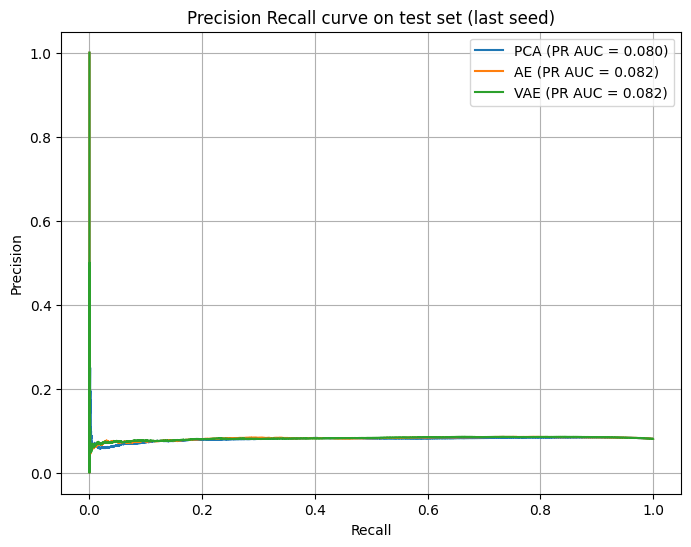

In [27]:
errors = [(error_pca_test, "PCA"), (error_ae_test, "AE"), (error_vae_test, "VAE")]

plt.figure(figsize=(8, 6))

for error, name in errors:

    precision, recall, _ = precision_recall_curve(y_test, error)
    plt.plot(recall, precision, label=f"{name} (PR AUC = {average_precision_score(y_test, error):.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision Recall curve on test set (last seed)")
plt.grid(True)
plt.legend()
plt.savefig("precision_recall.jpg")
plt.show()

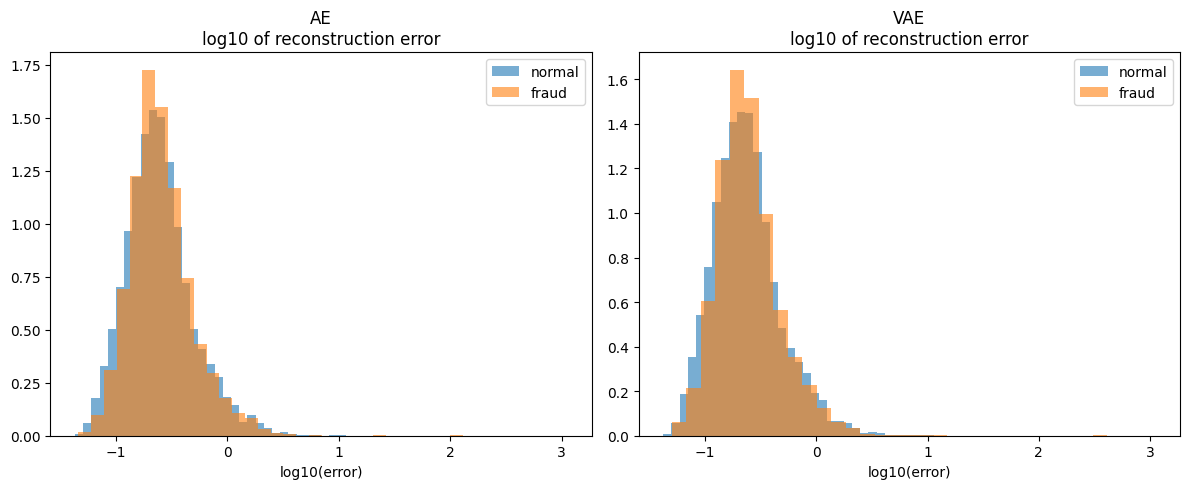

In [28]:
plt.figure(figsize=(12, 5))

for i, (error, name) in enumerate(errors[1:]):

    plt.subplot(1, 2, i + 1)
    plt.hist(np.log10(error[y_test == 0]), bins=60, alpha=0.6, density=True, label="normal")
    plt.hist(np.log10(error[y_test == 1]), bins=30, alpha=0.6, density=True, label="fraud")
    plt.title(f"{name}\nlog10 of reconstruction error")
    plt.xlabel("log10(error)")
    plt.legend()

plt.tight_layout()
plt.savefig("errors.jpg")
plt.show()